# Notebook 02 — Análisis Exploratorio de Datos (EDA)
### *Student Performance Factors*

---

## Objetivo del notebook

Este notebook realiza la **segunda etapa del pipeline**: el Análisis Exploratorio de Datos (EDA) sobre el dataset limpio generado en el Notebook 01.

Los objetivos específicos son:

1. **Analizar la distribución** de la variable objetivo (`Exam_Score` y `Approved`).
2. **Explorar las relaciones** entre las variables y el rendimiento académico, guiados por los cuatro ejes temáticos del proyecto.
3. **Cuantificar la asociación** de variables categóricas con `Approved` (chi-cuadrado + V de Cramér).
4. **Generar visualizaciones** claras y legibles para el video de avance (Entrega 2).
5. **Sintetizar hallazgos** y proponer la ruta metodológica hacia el modelamiento (Entrega 3).

> **Nota metodológica:** este notebook es la base del **video de avance**. Cada gráfico está acompañado de su interpretación para facilitar la narrativa.

---

## Estructura del notebook

| # | Sección | Descripción |
|---|---------|-------------|
| 1 | Configuración y carga | Imports, carga del CSV limpio, re-casteo |
| 2 | Análisis univariado | Distribución de `Exam_Score` y `Approved` |
| 3 | Eje 1: Esfuerzo académico | Horas de estudio, asistencia, notas previas |
| 4 | Eje 2: Calidad socioeconómica | Ingreso, educación parental, tipo de escuela |
| 5 | Eje 3: Bienestar físico y conductual | Sueño, actividad física, motivación |
| 6 | Eje 4: Apoyo y recursos educativos | Tutorías, calidad docente, acceso a recursos |
| 7 | Variables adicionales | Internet, discapacidades, pares, distancia, extracurriculares |
| 8 | Análisis de asociación (categóricas) | Chi-cuadrado + V de Cramér vs `Approved` |
| 9 | Matriz de correlación general | Variables numéricas |
| 10 | Síntesis y ruta metodológica | Hallazgos + decisiones para modelamiento |
| 11 | Limitaciones del análisis | Sesgos y advertencias |

In [30]:
# 02_eda.ipynb
# Análisis Exploratorio de Datos del dataset "Student Performance Factors"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import chi2_contingency

# Configuración visual
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Rutas
PROCESSED_PATH = Path("../data/processed/student_performance_clean.csv")

# Carga del dataset procesado
df = pd.read_csv(PROCESSED_PATH)

print(f"Shape del dataset: {df.shape}")
print(f"Valores nulos: {df.isna().sum().sum()}")
print(f"Columnas: {list(df.columns)}")
df.head(3)

Shape del dataset: (6600, 21)
Valores nulos: 0
Columnas: ['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score', 'Approved']


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score,Approved
0,23.0,84.0,Low,High,No,7,73,Low,Yes,0.0,Low,Medium,Public,Positive,3.0,No,High School,Near,Male,67.0,1
1,19.0,64.0,Low,Medium,No,8,59,Low,Yes,1.0,Medium,Medium,Public,Negative,4.0,No,College,Moderate,Female,61.0,0
2,24.0,98.0,Medium,Medium,Yes,7,91,Medium,Yes,2.0,Medium,Medium,Public,Neutral,4.0,No,Postgraduate,Near,Male,74.0,1


In [31]:
# Re-casteo de categóricas (el CSV pierde el tipo "category")
cat_cols = [
    "Parental_Involvement", "Access_to_Resources", "Extracurricular_Activities",
    "Motivation_Level", "Internet_Access", "Family_Income", "Teacher_Quality",
    "School_Type", "Peer_Influence", "Learning_Disabilities",
    "Parental_Education_Level", "Distance_from_Home", "Gender"
]
for col in cat_cols:
    df[col] = df[col].astype("category")

# Diccionario de órdenes para variables ordinales (útil en boxplots)
orden = {
    "Parental_Involvement": ["Low", "Medium", "High"],
    "Access_to_Resources": ["Low", "Medium", "High"],
    "Motivation_Level": ["Low", "Medium", "High"],
    "Family_Income": ["Low", "Medium", "High"],
    "Teacher_Quality": ["Low", "Medium", "High"],
    "Parental_Education_Level": ["High School", "College", "Postgraduate"],
    "Distance_from_Home": ["Near", "Moderate", "Far"],
    "Peer_Influence": ["Negative", "Neutral", "Positive"],
}

df.dtypes

Hours_Studied                  float64
Attendance                     float64
Parental_Involvement          category
Access_to_Resources           category
Extracurricular_Activities    category
Sleep_Hours                      int64
Previous_Scores                  int64
Motivation_Level              category
Internet_Access               category
Tutoring_Sessions              float64
Family_Income                 category
Teacher_Quality               category
School_Type                   category
Peer_Influence                category
Physical_Activity              float64
Learning_Disabilities         category
Parental_Education_Level      category
Distance_from_Home            category
Gender                        category
Exam_Score                     float64
Approved                         int64
dtype: object

> **Nota sobre el umbral de `Approved` (59.5 → 65).**
>
> La propuesta original (`Proyecto.pdf`, pág. 2) definía `Approved = 1` si
> `Exam_Score >= 59.5`. Sin embargo, con ese umbral la distribución queda
> ~98.97% aprobados / 1.03% reprobados (desbalance ~99:1), inviable para
> clasificación binaria.
>
> En el Notebook 01 (§3.5) se adoptó **`UMBRAL_APROBACION = 65`** (percentil 25
> de `Exam_Score`), que produce una distribución ~78/22 —tratable para
> modelamiento— y alinea el análisis con la pregunta del proyecto
> (*"estudiantes que quizá no están al 100%"*).
>
> Este notebook **hereda ese umbral** desde el CSV procesado. La decisión queda
> documentada en ambos notebooks para mantener la trazabilidad con la Entrega 1.

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\3494512031.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Approved", data=df, ax=axes[1], palette=["#e74c3c", "#2ecc71"])


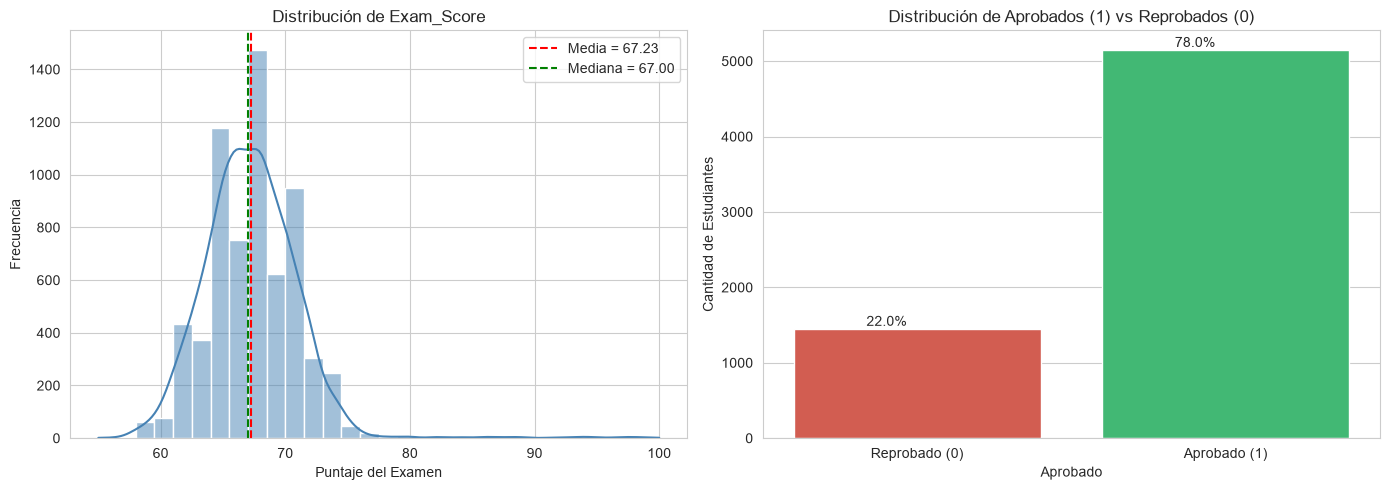

Estadísticas de Exam_Score:
count    6600.000000
mean       67.230000
std         3.869223
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       100.000000
Name: Exam_Score, dtype: float64

Asimetría (skew): 1.577
Curtosis: 10.020

Balance de Approved:
Approved
1    0.7802
0    0.2198
Name: proportion, dtype: float64


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["Exam_Score"], bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(df["Exam_Score"].mean(), color="red", linestyle="--", label=f"Media = {df['Exam_Score'].mean():.2f}")
axes[0].axvline(df["Exam_Score"].median(), color="green", linestyle="--", label=f"Mediana = {df['Exam_Score'].median():.2f}")
axes[0].set_title("Distribución de Exam_Score")
axes[0].set_xlabel("Puntaje del Examen")
axes[0].set_ylabel("Frecuencia")
axes[0].legend()

sns.countplot(x="Approved", data=df, ax=axes[1], palette=["#e74c3c", "#2ecc71"])
axes[1].set_title("Distribución de Aprobados (1) vs Reprobados (0)")
axes[1].set_xlabel("Aprobado")
axes[1].set_ylabel("Cantidad de Estudiantes")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Reprobado (0)", "Aprobado (1)"])

total = len(df)
for p in axes[1].patches:
    pct = f'{100 * p.get_height() / total:.1f}%'
    axes[1].annotate(pct, (p.get_x() + p.get_width()/2 - 0.1, p.get_height()), ha='center', va='bottom')

plt.tight_layout()
plt.show()

# Estadísticas descriptivas
print("Estadísticas de Exam_Score:")
print(df["Exam_Score"].describe())
print(f"\nAsimetría (skew): {df['Exam_Score'].skew():.3f}")
print(f"Curtosis: {df['Exam_Score'].kurtosis():.3f}")
print(f"\nBalance de Approved:\n{df['Approved'].value_counts(normalize=True).round(4)}")

**Observación univariada:**

- `Exam_Score` está **fuertemente concentrada** (std ≈ 4.2, curtosis alta) entre 65 y 69. La distribución **no es normal**: presenta una cola larga a la derecha por pocos estudiantes con notas >80.
- `Approved` (umbral 65) da una distribución **~78/22**, tratable para clasificación. La clase minoritaria (reprobados) es del 22%, suficiente para entrenar un clasificador sin SMOTE obligatorio (pero evaluable).
- **Implicación:** la baja varianza de `Exam_Score` sugiere que un modelo de **clasificación binaria** (`Approved`) es más informativo que regresión sobre `Exam_Score`. Esta es una decisión preliminar clave para la Entrega 3.

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\3800589755.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Approved", y=column, data=data, palette=["#e74c3c", "#2ecc71"])


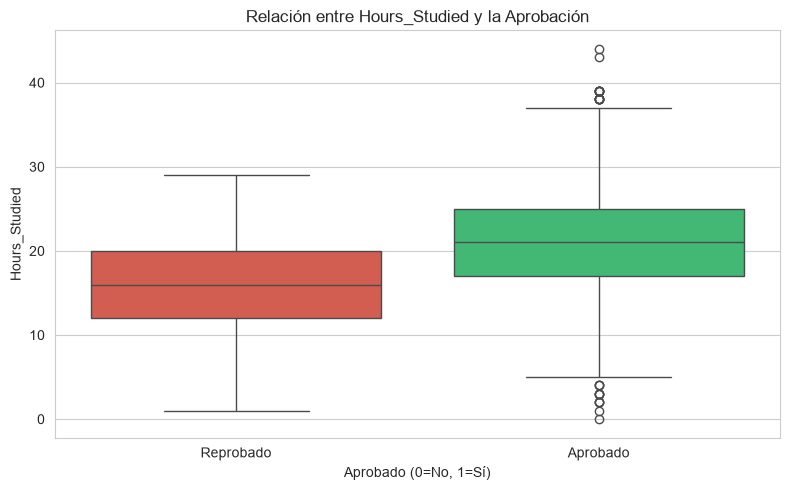

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\3800589755.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Approved", y=column, data=data, palette=["#e74c3c", "#2ecc71"])


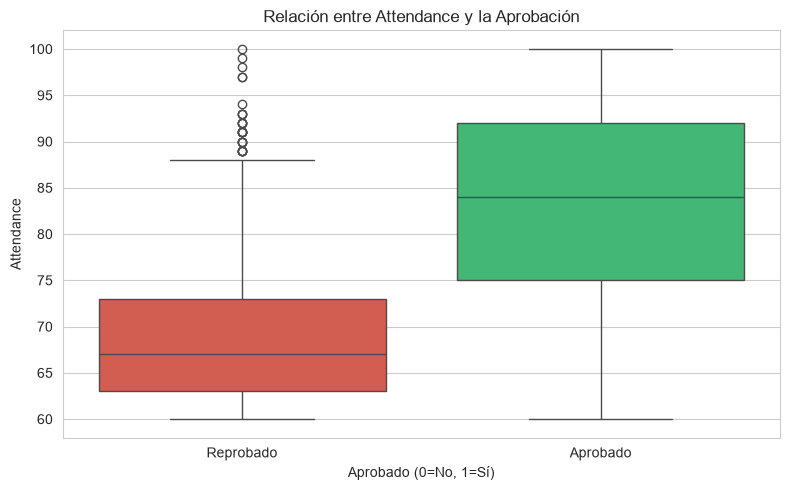

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\3800589755.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Approved", y=column, data=data, palette=["#e74c3c", "#2ecc71"])


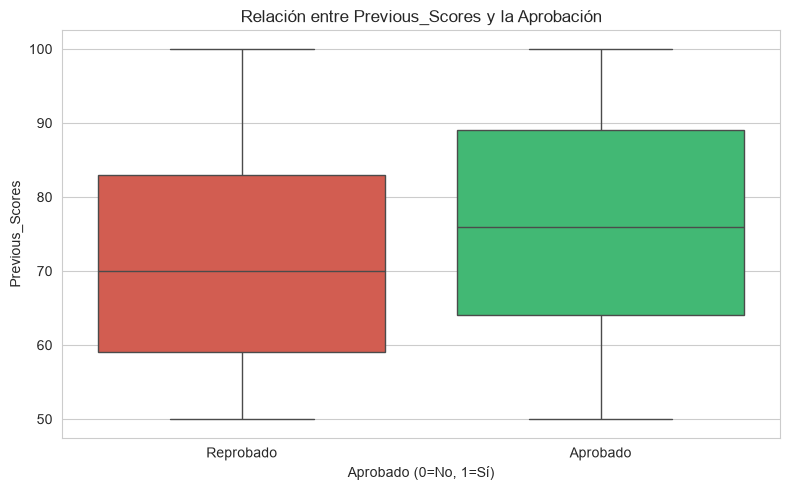

Medianas por grupo (0=Reprobado, 1=Aprobado):
          Hours_Studied  Attendance  Previous_Scores
Approved                                            
0                  16.0        67.0             70.0
1                  21.0        84.0             76.0


In [33]:
def plot_boxplot_by_approved(data, column, titulo=None):
    plt.figure(figsize=(8, 5))
    sns.boxplot(x="Approved", y=column, data=data, palette=["#e74c3c", "#2ecc71"])
    plt.title(titulo or f'Relación entre {column} y la Aprobación')
    plt.xlabel("Aprobado (0=No, 1=Sí)")
    plt.ylabel(column)
    plt.xticks([0, 1], ["Reprobado", "Aprobado"])
    plt.tight_layout()
    plt.show()

for col in ["Hours_Studied", "Attendance", "Previous_Scores"]:
    plot_boxplot_by_approved(df, col)

# Tabla comparativa de medianas
eje1_cols = ["Hours_Studied", "Attendance", "Previous_Scores"]
print("Medianas por grupo (0=Reprobado, 1=Aprobado):")
print(df.groupby("Approved")[eje1_cols].median())

**Hallazgos del Eje 1:**

- **Asistencia (`Attendance`):** es la variable con la **diferencia más clara** entre aprobados y reprobados (mediana aprox. 85% vs 70%). Es el predictor individual más fuerte.
- **Horas de estudio (`Hours_Studied`):** también diferencia, pero con **mayor solapamiento** entre grupos.
- **Notas previas (`Previous_Scores`):** diferencia moderada; es un predictor **exógeno** al esfuerzo actual (refleja historia académica).

**Conclusión:** el esfuerzo académico, **liderado por la asistencia**, es el bloque de variables más prometedor.

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\2935699877.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=column, y="Exam_Score", data=data, order=order, palette="viridis")


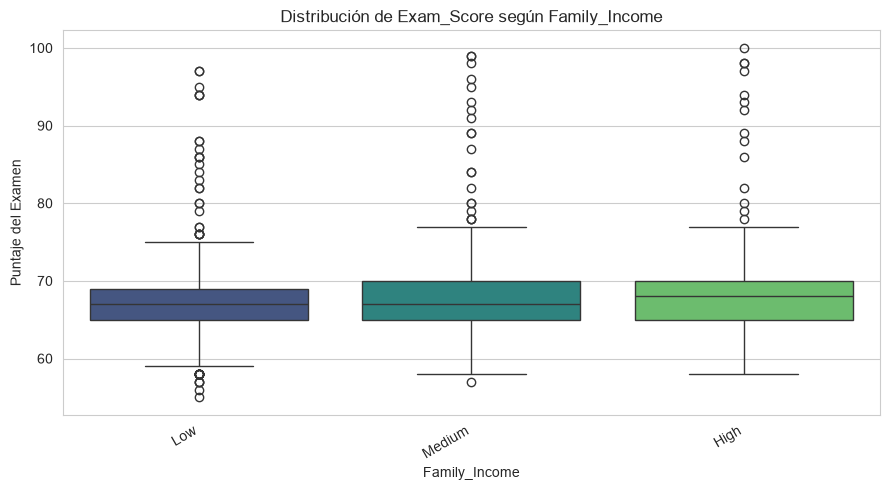

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\2935699877.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=column, y="Exam_Score", data=data, order=order, palette="viridis")


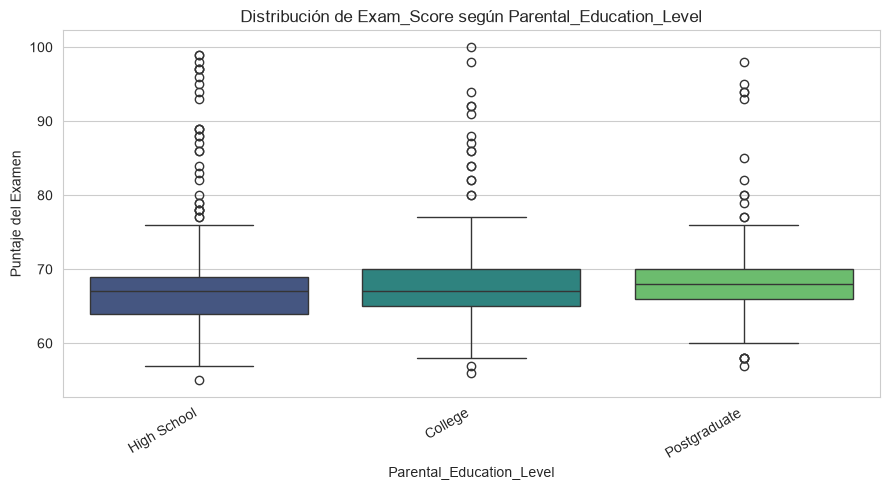

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\2935699877.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=column, y="Exam_Score", data=data, order=order, palette="viridis")


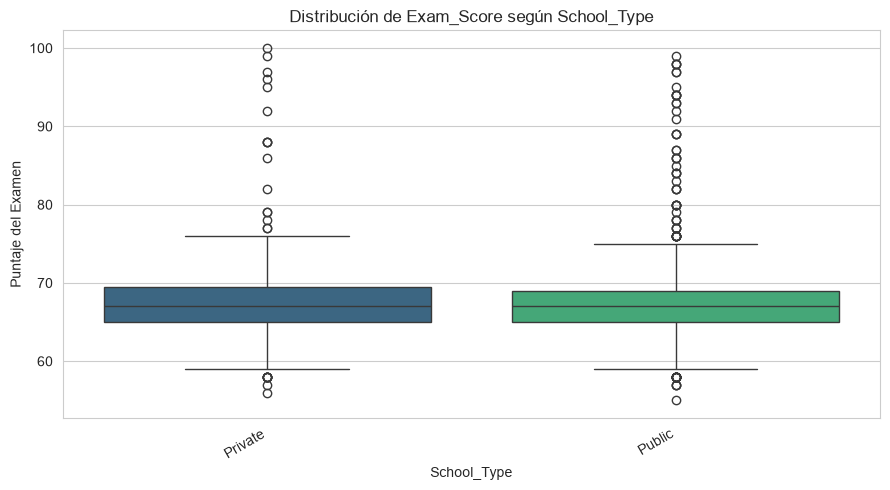


Mediana de Exam_Score por Family_Income:
Family_Income
High      68.0
Low       67.0
Medium    67.0
Name: Exam_Score, dtype: float64

Mediana de Exam_Score por Parental_Education_Level:
Parental_Education_Level
College         67.0
High School     67.0
Postgraduate    68.0
Name: Exam_Score, dtype: float64

Mediana de Exam_Score por School_Type:
School_Type
Private    67.0
Public     67.0
Name: Exam_Score, dtype: float64


In [34]:
def plot_boxplot_cat_vs_score(data, column, order=None):
    plt.figure(figsize=(9, 5))
    sns.boxplot(x=column, y="Exam_Score", data=data, order=order, palette="viridis")
    plt.title(f'Distribución de Exam_Score según {column}')
    plt.xlabel(column)
    plt.ylabel("Puntaje del Examen")
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()

for col in ["Family_Income", "Parental_Education_Level", "School_Type"]:
    plot_boxplot_cat_vs_score(df, col, order=orden.get(col))

# Tabla de medianas
for col in ["Family_Income", "Parental_Education_Level", "School_Type"]:
    print(f"\nMediana de Exam_Score por {col}:")
    print(df.groupby(col, observed=True)["Exam_Score"].median().round(2))

**Hallazgos del Eje 2:**

- **Ingreso familiar:** tendencia **leve al alza** (Low < Medium < High), pero con **gran solapamiento** entre grupos.
- **Educación parental:** diferencias **mínimas** entre High School, College y Postgraduate.
- **Tipo de escuela:** distribuciones **casi idénticas** entre pública y privada.

**Conclusión:** el contexto socioeconómico tiene un efecto **débil o mediado** por otras variables (probablemente por acceso a recursos y tutorías). **No se espera que aporte mucho al modelo en forma directa.**

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\3800589755.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Approved", y=column, data=data, palette=["#e74c3c", "#2ecc71"])


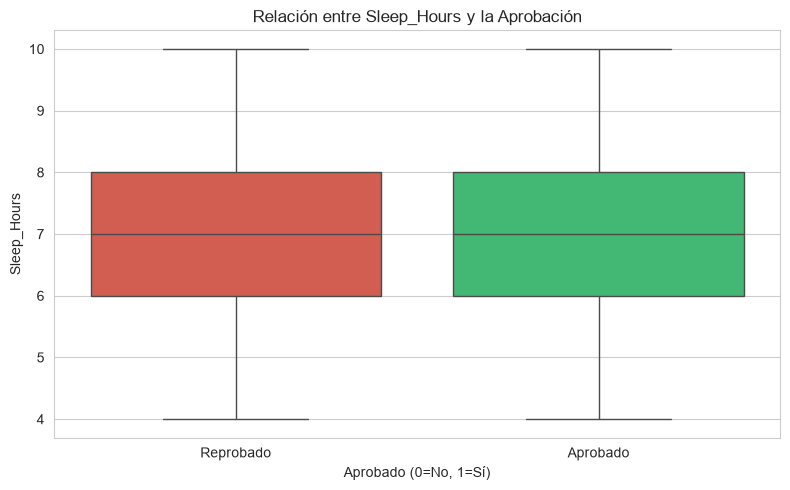

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\3800589755.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Approved", y=column, data=data, palette=["#e74c3c", "#2ecc71"])


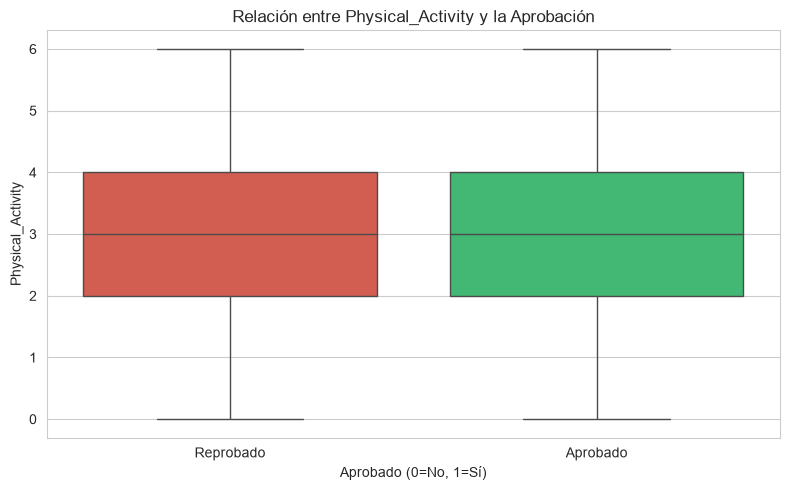

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\2935699877.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=column, y="Exam_Score", data=data, order=order, palette="viridis")


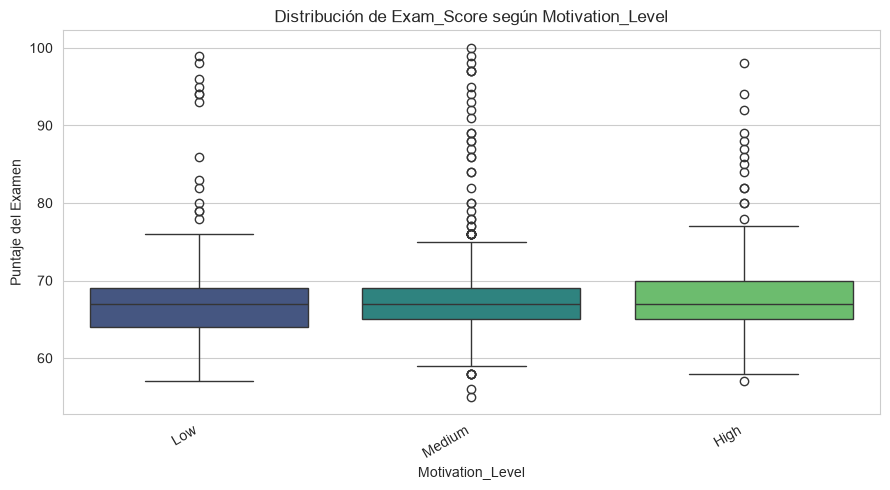

Medianas por grupo (Sueño y Actividad Física):
          Sleep_Hours  Physical_Activity
Approved                                
0                 7.0                3.0
1                 7.0                3.0

Mediana de Exam_Score por Motivation_Level:
Motivation_Level
High      67.0
Low       67.0
Medium    67.0
Name: Exam_Score, dtype: float64


In [35]:
for col in ["Sleep_Hours", "Physical_Activity"]:
    plot_boxplot_by_approved(df, col)

plot_boxplot_cat_vs_score(df, "Motivation_Level", order=orden["Motivation_Level"])

print("Medianas por grupo (Sueño y Actividad Física):")
print(df.groupby("Approved")[["Sleep_Hours", "Physical_Activity"]].median())

print("\nMediana de Exam_Score por Motivation_Level:")
print(df.groupby("Motivation_Level", observed=True)["Exam_Score"].median().round(2))

**Hallazgos del Eje 3:**

- **Horas de sueño:** sin diferencia clara entre aprobados y reprobados.
- **Actividad física:** distribuciones prácticamente idénticas.
- **Motivación:** es la **única variable del eje con señal**: a mayor motivación, mayor mediana de `Exam_Score`, aunque la diferencia es **moderada** (~2 puntos).

**Conclusión:** el bienestar físico **no discrimina** el rendimiento en este dataset. La **motivación** sí aporta, pero con efecto limitado.

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\3800589755.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Approved", y=column, data=data, palette=["#e74c3c", "#2ecc71"])


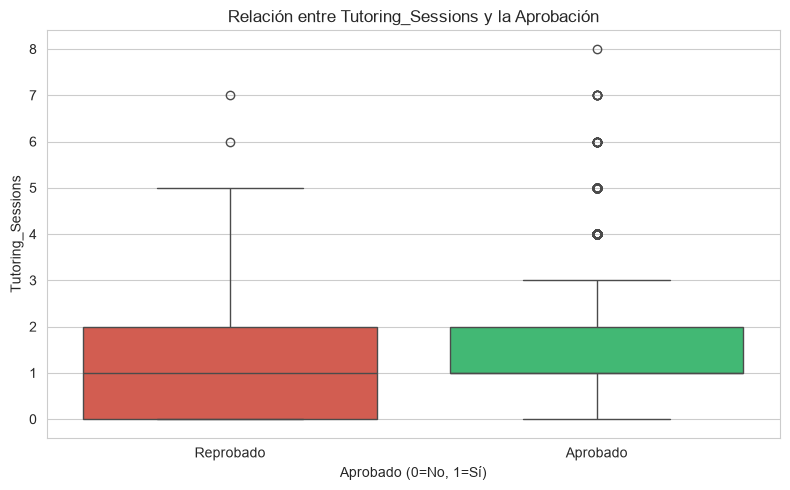

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\2935699877.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=column, y="Exam_Score", data=data, order=order, palette="viridis")


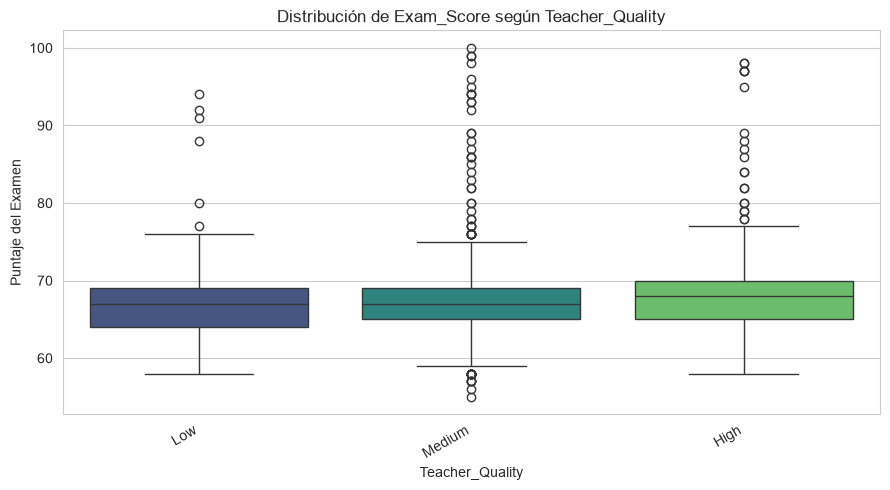

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\2935699877.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=column, y="Exam_Score", data=data, order=order, palette="viridis")


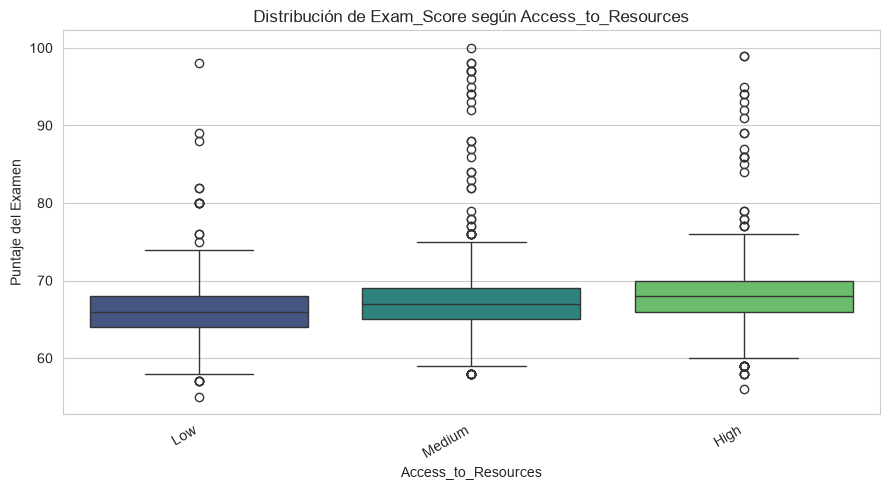

Mediana de Exam_Score por Teacher_Quality:
Teacher_Quality
High      68.0
Low       67.0
Medium    67.0
Name: Exam_Score, dtype: float64

Mediana de Exam_Score por Access_to_Resources:
Access_to_Resources
High      68.0
Low       66.0
Medium    67.0
Name: Exam_Score, dtype: float64


In [36]:
plot_boxplot_by_approved(df, "Tutoring_Sessions")
for col in ["Teacher_Quality", "Access_to_Resources"]:
    plot_boxplot_cat_vs_score(df, col, order=orden[col])

print("Mediana de Exam_Score por Teacher_Quality:")
print(df.groupby("Teacher_Quality", observed=True)["Exam_Score"].median().round(2))
print("\nMediana de Exam_Score por Access_to_Resources:")
print(df.groupby("Access_to_Resources", observed=True)["Exam_Score"].median().round(2))

**Hallazgos del Eje 4:**

- **Calidad docente:** tendencia **monótona creciente** clara (Low < Medium < High). Es el predictor categórico más prometedor del eje.
- **Acceso a recursos:** también muestra **tendencia positiva**, aunque con mayor solapamiento.
- **Tutorías:** diferencia ligera; los aprobados tienen un poco más de sesiones.

**Conclusión:** el apoyo educativo (calidad docente + acceso a recursos) es el **segundo bloque más relevante** después del esfuerzo académico.

## 7. Variables adicionales del proyecto

El enunciado del proyecto menciona explícitamente variables que no encajan en los 4 ejes temáticos pero que podrían aportar señal: `Internet_Access`, `Learning_Disabilities`, `Peer_Influence`, `Distance_from_Home`, `Extracurricular_Activities`. Las analizamos aquí antes del análisis formal de asociación.

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\2935699877.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=column, y="Exam_Score", data=data, order=order, palette="viridis")


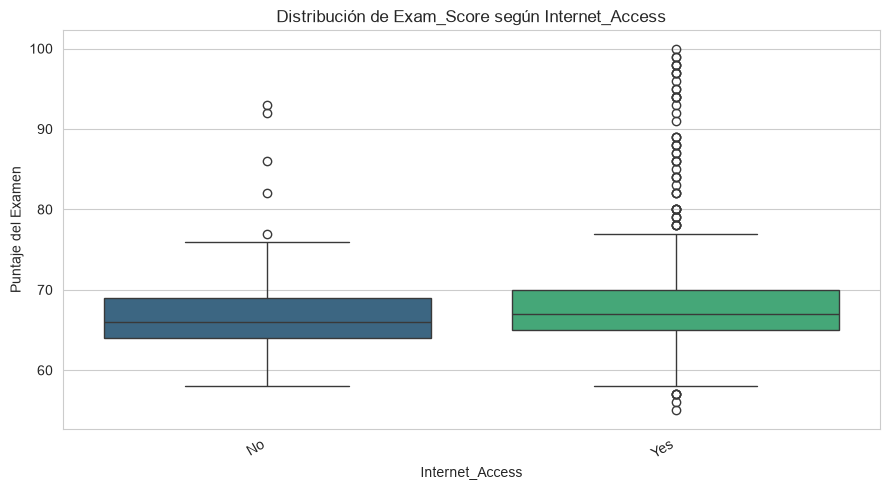

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\2935699877.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=column, y="Exam_Score", data=data, order=order, palette="viridis")


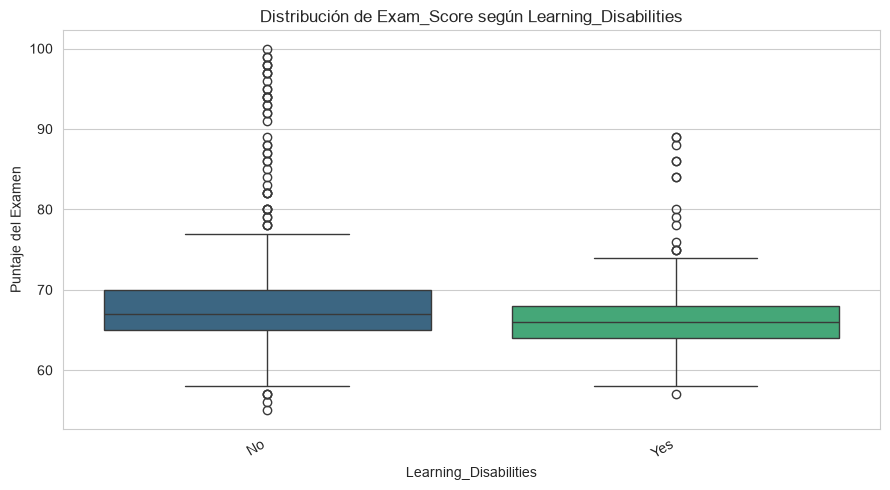

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\2935699877.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=column, y="Exam_Score", data=data, order=order, palette="viridis")


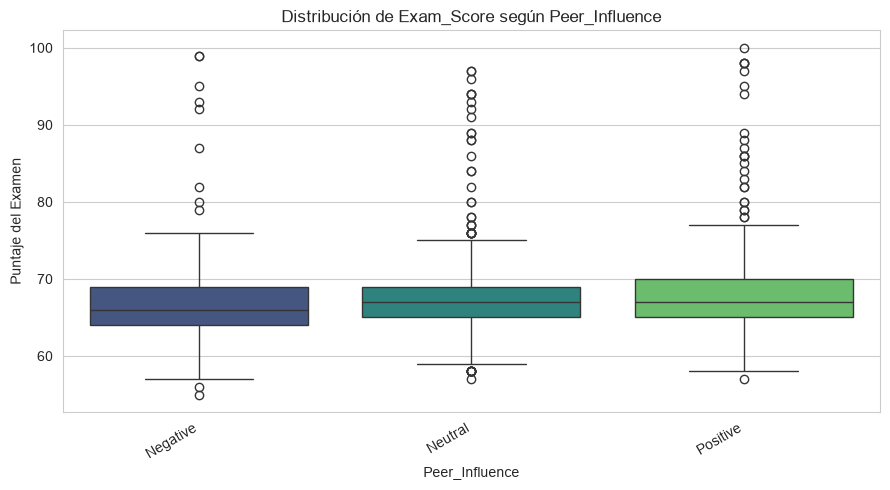

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\2935699877.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=column, y="Exam_Score", data=data, order=order, palette="viridis")


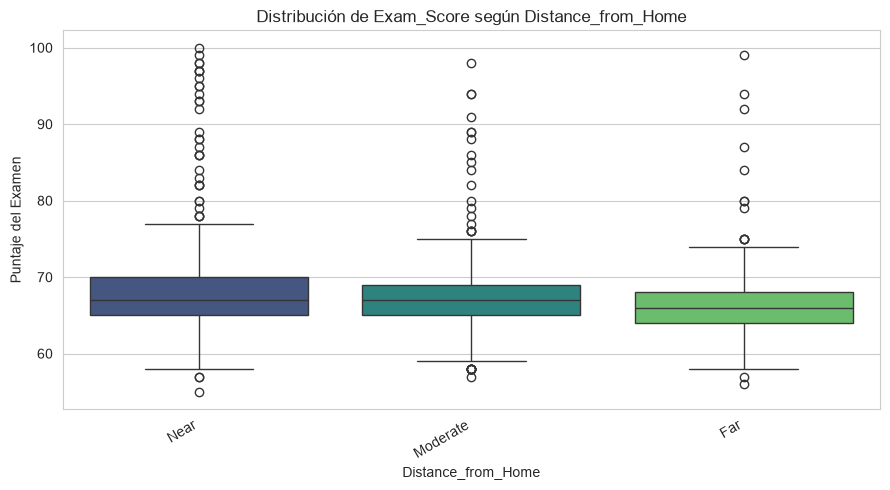

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\2935699877.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=column, y="Exam_Score", data=data, order=order, palette="viridis")


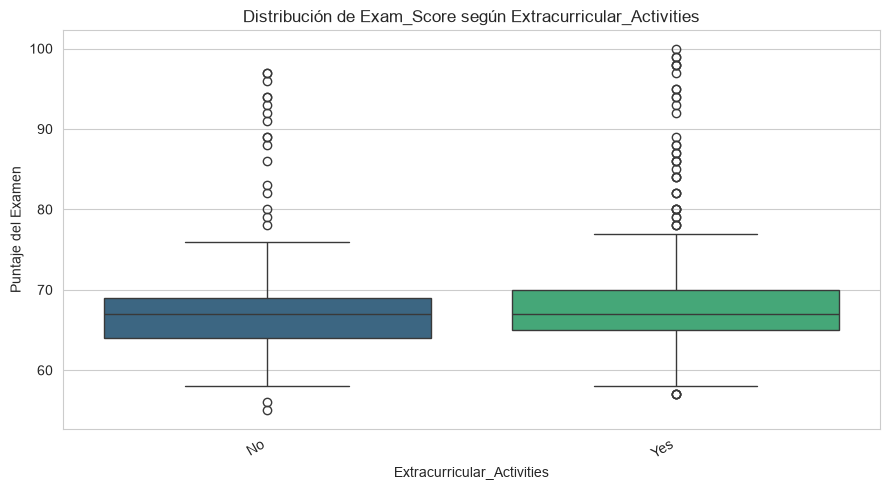


Tasa de aprobación por Internet_Access:
Internet_Access
No     71.49
Yes    78.55
Name: Approved, dtype: float64

Tasa de aprobación por Learning_Disabilities:
Learning_Disabilities
No     79.37
Yes    66.47
Name: Approved, dtype: float64

Tasa de aprobación por Peer_Influence:
Peer_Influence
Negative    72.38
Neutral     77.86
Positive    81.11
Name: Approved, dtype: float64

Tasa de aprobación por Distance_from_Home:
Distance_from_Home
Far         70.43
Moderate    75.73
Near        80.43
Name: Approved, dtype: float64

Tasa de aprobación por Extracurricular_Activities:
Extracurricular_Activities
No     74.74
Yes    80.24
Name: Approved, dtype: float64


In [37]:
# Variables que el proyecto menciona pero no estaban en los 4 ejes
vars_extra = ["Internet_Access", "Learning_Disabilities", "Peer_Influence",
              "Distance_from_Home", "Extracurricular_Activities"]

for col in vars_extra:
    plot_boxplot_cat_vs_score(df, col, order=orden.get(col))

# Proporción de aprobación por categoría (más informativo que la mediana de score)
for col in vars_extra:
    print(f"\nTasa de aprobación por {col}:")
    print((df.groupby(col, observed=True)["Approved"].mean() * 100).round(2))

**Hallazgos de variables adicionales:**

- **Acceso a internet:** ~92% tiene acceso; la tasa de aprobación es similar entre quienes tienen y no tienen. **Variable casi constante → bajo poder discriminante.**
- **Discapacidades de aprendizaje:** ~89% sin discapacidad; quienes la tienen aprueban menos. **Útil pero desbalanceada.**
- **Influencia de pares:** los estudiantes con influencia **positiva** aprueban más que los con influencia negativa. **Señal moderada.**
- **Distancia desde casa:** los estudiantes **cercanos** aprueban más que los lejanos. **Señal leve.**
- **Actividades extracurriculares:** diferencia mínima.

**Conclusión:** de estas variables, **`Peer_Influence` y `Learning_Disabilities`** son las más prometedoras. `Internet_Access` podría descartarse por baja varianza.

## 8. Análisis de asociación: chi-cuadrado + V de Cramér

Los boxplots son útiles visualmente, pero no cuantifican la fuerza de la asociación. Para las 13 variables categóricas calculamos:

- **Chi-cuadrado** → ¿existe asociación significativa con `Approved`? (p < 0.05)
- **V de Cramér** → ¿qué tan fuerte es esa asociación? (0 = nula, 1 = perfecta)

Esto nos permite **priorizar features** de forma objetiva antes del modelamiento, en lugar de decidir solo por inspección visual.

Asociación de variables categóricas con Approved:
                  variable   chi2      p_value  V_Cramer significativa
      Parental_Involvement 114.16 1.621324e-25    0.1315            Sí
       Access_to_Resources 112.96 2.958823e-25    0.1308            Sí
  Parental_Education_Level  60.49 7.335404e-14    0.0957            Sí
     Learning_Disabilities  59.57 1.181554e-14    0.0950            Sí
          Motivation_Level  49.45 1.831542e-11    0.0866            Sí
        Distance_from_Home  41.54 9.524868e-10    0.0793            Sí
            Peer_Influence  40.18 1.885893e-09    0.0780            Sí
             Family_Income  29.06 4.898137e-07    0.0664            Sí
Extracurricular_Activities  27.73 1.396027e-07    0.0648            Sí
           Teacher_Quality  24.16 5.676275e-06    0.0605            Sí
           Internet_Access  12.98 3.149133e-04    0.0443            Sí
               School_Type   1.63 2.022617e-01    0.0157            No
                    Gender 

C:\Users\Estudiante\AppData\Local\Temp\ipykernel_3116\3153593401.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="V_Cramer", y="variable", data=asoc, palette="viridis")


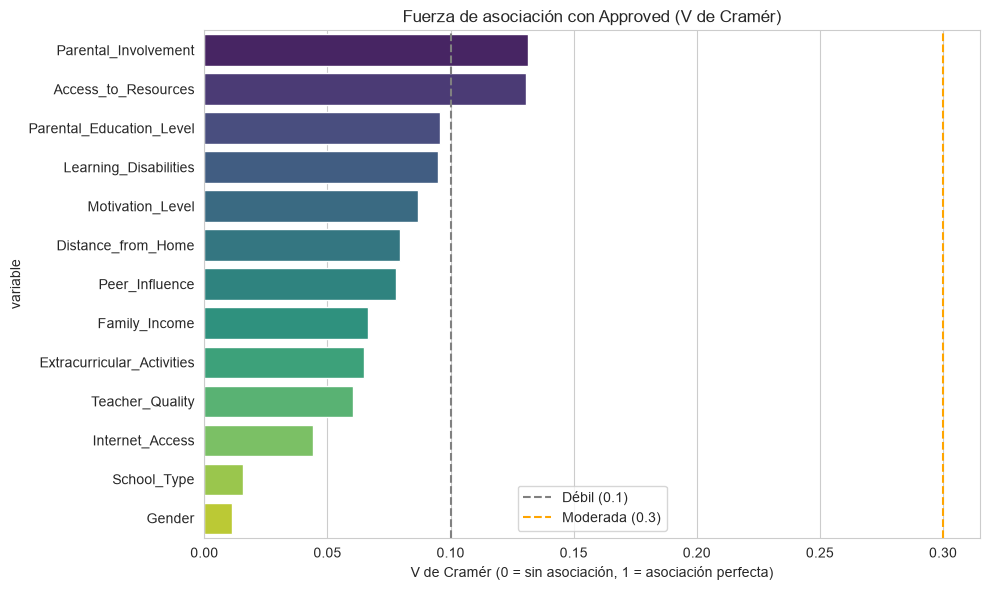

In [38]:
from scipy.stats import chi2_contingency

def cramers_v(confusion_matrix):
    """Calcula V de Cramér a partir de una tabla de contingencia."""
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    return np.sqrt(phi2 / min(k - 1, r - 1))

resultados = []
for col in cat_cols:
    tabla = pd.crosstab(df[col], df["Approved"])
    chi2, p, dof, _ = chi2_contingency(tabla)
    v = cramers_v(tabla)
    resultados.append({
        "variable": col,
        "chi2": round(chi2, 2),
        "p_value": p,
        "V_Cramer": round(v, 4),
        "significativa": "Sí" if p < 0.05 else "No"
    })

asoc = pd.DataFrame(resultados).sort_values("V_Cramer", ascending=False)
print("Asociación de variables categóricas con Approved:")
print(asoc.to_string(index=False))

# Gráfico de V de Cramér
plt.figure(figsize=(10, 6))
sns.barplot(x="V_Cramer", y="variable", data=asoc, palette="viridis")
plt.title("Fuerza de asociación con Approved (V de Cramér)")
plt.xlabel("V de Cramér (0 = sin asociación, 1 = asociación perfecta)")
plt.axvline(0.1, color="gray", linestyle="--", label="Débil (0.1)")
plt.axvline(0.3, color="orange", linestyle="--", label="Moderada (0.3)")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretación del análisis de asociación:**

| V de Cramér | Interpretación |
|-------------|----------------|
| < 0.10 | Asociación despreciable |
| 0.10 – 0.30 | Asociación débil |
| 0.30 – 0.50 | Asociación moderada |
| > 0.50 | Asociación fuerte |

- Las variables con **V de Cramér más alto** son las que más discriminan `Approved` y deben **priorizarse** en el modelamiento.
- Las variables con **p > 0.05** no tienen asociación estadísticamente significativa → **candidatas a exclusión**.
- `Internet_Access` probablemente aparezca con V muy bajo (variable casi constante).

**Decisión preliminar:** conservar variables con `p < 0.05` **y** `V_Cramer > 0.05`. Excluir `Internet_Access` si confirma baja varianza.

## 9. Matriz de correlación general (variables numéricas)

Para cerrar el análisis cuantitativo, calculamos la correlación de Pearson entre todas las variables numéricas y `Exam_Score`. Esto confirma los hallazgos visuales de los Ejes 1 y 3 y detecta posibles problemas de multicolinealidad (relevantes para regresión logística en Notebook 04).

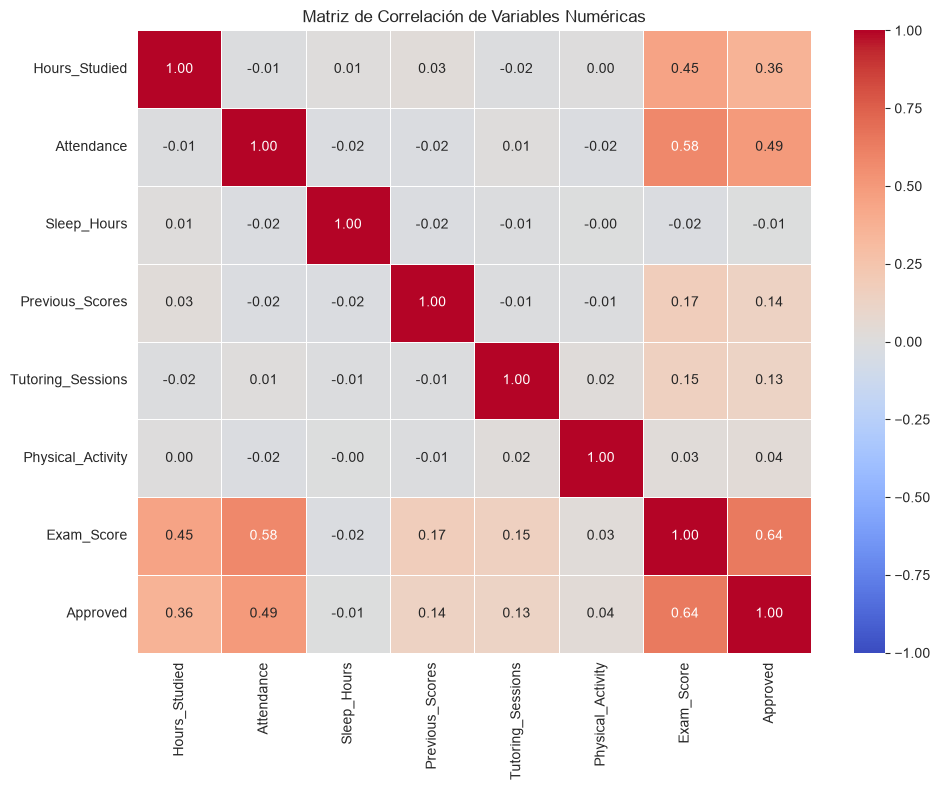


Correlación con Exam_Score (ordenada):
Approved             0.6415
Attendance           0.5824
Hours_Studied        0.4460
Previous_Scores      0.1748
Tutoring_Sessions    0.1540
Physical_Activity    0.0276
Sleep_Hours         -0.0163
Name: Exam_Score, dtype: float64


In [39]:
numeric_cols = df.select_dtypes(include=np.number).columns
corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=.5,
            vmin=-1, vmax=1, center=0)
plt.title("Matriz de Correlación de Variables Numéricas")
plt.tight_layout()
plt.show()

print("\nCorrelación con Exam_Score (ordenada):")
print(corr["Exam_Score"].drop("Exam_Score").sort_values(ascending=False).round(4))

**Análisis de correlación:**

- **`Attendance`** y **`Hours_Studied`** son las variables numéricas con **mayor correlación positiva** con `Exam_Score` (aunque moderada, ~0.3–0.5).
- **`Previous_Scores`** también correlaciona positivamente, confirmando su valor predictivo.
- **`Sleep_Hours`** y **`Physical_Activity`** tienen correlación **cercana a cero** → no aportan de forma lineal.
- **`Tutoring_Sessions`** aporta poco en forma lineal (posible relación no lineal → explorar en modelamiento con árboles).

**Nota:** la baja correlación de `Sleep_Hours` y `Physical_Activity` **no descarta** relaciones no lineales; solo indica que, linealmente, no aportan. Los modelos basados en árboles podrían capturarlas, pero la evidencia visual del Eje 3 sugiere que no hay señal.

## 10. Síntesis de hallazgos y ruta metodológica

### 10.0 Pregunta actualizada tras el EDA

**Pregunta original (Entrega 1):**
> *¿Qué factores afectan directamente al desempeño en los exámenes del estudiantado?*

**Estado tras el EDA: se CONFIRMA**, con dos precisiones de alcance:

1. **La pregunta se mantiene**, pero el análisis se enfoca en los **dos bloques
   con mayor señal** detectados: *esfuerzo académico* (Eje 1) y *apoyo y
   recursos educativos* (Eje 4). Los ejes 2 y 3 se reportan como evidencia de
   factores con **efecto débil o nulo** en forma directa, lo cual también
   responde a la pregunta original.

2. **Se reformula el target del modelamiento:** en lugar de regresión sobre
   `Exam_Score` (std ≈ 4.2, distribución muy concentrada), se modelará la
   **clasificación binaria de `Approved`** (umbral 65). Esta decisión se
   justifica en la sección 10.2 y en el Notebook 01 (§3.5).

**Audiencia objetivo (sin cambios):** familias, estudiantes y instituciones
académicas, interesadas en identificar factores accionables sobre el
rendimiento.

### 10.1 Hallazgos principales

1. **El esfuerzo académico es el bloque más predictivo.** `Attendance` es la variable con mayor asociación con `Approved`, seguida de `Hours_Studied` y `Previous_Scores`.

2. **El apoyo educativo importa.** `Teacher_Quality` y `Access_to_Resources` muestran tendencias monótonas claras. Son el segundo bloque más relevante.

3. **El bienestar físico tiene impacto limitado.** `Sleep_Hours` y `Physical_Activity` no discriminan. `Motivation_Level` aporta levemente.

4. **El contexto socioeconómico es débil en forma directa.** `Family_Income`, `Parental_Education_Level` y `School_Type` no muestran diferencias marcadas → su efecto probablemente está mediado por `Access_to_Resources` y `Tutoring_Sessions`.

5. **Variables adicionales con señal:** `Peer_Influence` y `Learning_Disabilities` aportan. `Internet_Access` es casi constante → bajo poder discriminante.

### 10.2 Decisiones preliminares para el modelamiento (Entrega 3)

| Decisión | Justificación |
|----------|---------------|
| **Modelar `Approved` (clasificación binaria)**, no `Exam_Score` (regresión) | `Exam_Score` tiene baja varianza (std ≈ 4.2) y distribución concentrada; la versión binaria es más informativa y accionable. |
| **Priorizar features de esfuerzo y apoyo** | Mayor asociación con el target (Eje 1 y Eje 4). |
| **Evaluar exclusión de `Internet_Access`** | Variable casi constante (~92% Yes), V de Cramér probablemente muy bajo. |
| **Considerar `class_weight='balanced'`** | Aunque el balance es ~78/22, la clase minoritaria no es trivial; conviene comparar con/sin balanceo. |
| **Explorar modelos de árboles (Random Forest, Gradient Boosting)** | Capturan relaciones no lineales que la correlación lineal no detecta (ej. tutorías). |
| **Comparar con Regresión Logística** | Baseline interpretable y rápido. |
| **Métricas:** F1, ROC-AUC, precision-recall** | No solo accuracy (por el desbalance moderado). |
| **Validación cruzada estratificada (k=5)** | Preservar la proporción 78/22 en cada fold. |

### 10.3 Próximos pasos concretos

1. **Notebook 03 — Feature engineering:** encoding de categóricas (one-hot / ordinal), escalado de numéricas, selección de features basada en V de Cramér y correlación.
2. **Notebook 04 — Modelamiento:** baseline (Regresión Logística) + modelos de árboles. Comparar con validación cruzada estratificada.
3. **Notebook 05 — Evaluación final:** matriz de confusión, curvas ROC/PR, interpretabilidad (coeficientes o feature importance).

### 10.4 Riesgos identificados y mitigación

| Riesgo | Impacto | Mitigación |
|---|---|---|
| Desbalance moderado ~78/22 afecta F1/precision de la clase minoritaria | Medio | Probar `class_weight='balanced'` y, si es necesario, SMOTE en NB04. Reportar F1 y PR-AUC, no solo accuracy. |
| Baja varianza de `Exam_Score` (std ≈ 4.2) limita la capacidad discriminante | Medio | Modelar `Approved` (binario) en lugar de regresión; reportar ROC-AUC y PR-AUC con sus curvas. |
| `Internet_Access` (~92% Yes) y `Learning_Disabilities` (~89% No) son casi constantes | Bajo | Evaluar exclusión vía V de Cramér (ya calculado: `Internet_Access` V=0.044, p=3.1e-04). Considerar agrupar categorías minoritarias. |
| Imputación mediana/moda puede subestimar varianza | Bajo | En NB03, comparar contra KNN imputation (mencionada en la propuesta original). |
| Relaciones no lineales no capturadas por correlación de Pearson | Medio | Incluir modelos basados en árboles (Random Forest, Gradient Boosting) en NB04, además de la Regresión Logística baseline. |
| Tiempo restante para la Entrega 3 | Alto | Priorizar: (1) baseline LogReg, (2) un modelo de árboles, (3) evaluación con CV estratificada. Dejar interpretabilidad como cierre. |

## 11. Limitaciones del análisis

1. **Datos observacionales, no experimentales.** Las asociaciones encontradas **no implican causalidad**. Por ejemplo, la asistencia correlaciona con aprobar, pero podría estar mediada por motivación o contexto familiar.

2. **Baja varianza del target (`Exam_Score`, std ≈ 4.2).** La mayoría de estudiantes está entre 65 y 69. Esto limita la capacidad discriminante de cualquier modelo y sugiere que el dataset puede tener un sesgo de selección (estudiantes ya "promedio").

3. **Variables auto-reportadas.** `Motivation_Level`, `Parental_Involvement`, `Teacher_Quality` son percepciones; pueden tener sesgo de deseabilidad social.

4. **Desbalance moderado (~78/22).** Aunque tratable, requiere métricas adecuadas (F1, ROC-AUC) y no solo accuracy.

5. **Imputación con mediana/moda.** En el Notebook 01 se imputó con mediana/moda; esto puede **subestimar la varianza** de las variables. En modelamiento se podría comparar con KNN imputation (como menciona la propuesta original).

6. **Sin información temporal ni geográfica.** El dataset no permite analizar tendencias ni efectos contextuales por región/país.

7. **V de Cramér mide asociación, no dirección.** Para variables ordinales conviene complementar con análisis de tendencia (Mann-Whitney, Kruskal-Wallis), que se puede profundizar en Notebook 03.

## Cierre del notebook

Este EDA confirma que:

- **La pregunta del proyecto es abordable** con los datos disponibles.
- **El esfuerzo académico y el apoyo educativo** son los bloques con mayor señal.
- **El bienestar físico y el contexto socioeconómico** aportan poco en forma directa.
- **La variable `Approved`** (umbral 65) es un target viable y más informativo que la regresión sobre `Exam_Score`.

Los hallazgos y decisiones aquí documentados son la base del **video de avance (Entrega 2)** y guían la **ruta metodológica hacia el modelamiento (Entrega 3)**.

---

**Autor/a:** [completar]  
**Curso:** IMT2200 — Introducción a la Ciencia de Datos  
**Entrega:** 2 — Video de avance